# Kronenhöhe rund um Köhlerplätze (Kohlmeiler)

Seminar 715: Application GIS in Protected Areas, Schweizerischer Nationalpark

Dieses Notebook enthält die gesamte Auswertung. Die Abschnitte bauen aufeinander auf und werden von oben nach unten ausgeführt.

| Abschnitt | Inhalt |
|---|---|
| 1 | Einstellungen |
| 2 | Ringanalyse 0–8 m (feine Skala) |
| 3 | Ringanalyse 0–50 m |
| 4 | Räumliche Lage der Kilns (Nachbarn, Gruppen) |
| 5 | Ringmittel und Streuung (SD) |
| 6 | Vier ausgewählte Kilns |
| 7 | Überblick über alle Kilns (PDF) |
| 8 | Kontrollpunkte (optional) |
| 9 | Grenzen der Auswertung |

**Dateien im selben Ordner wie dieses Notebook:** `kiln_ring_analysis_function.py`, `plot_kiln_rings_function.py`, `kohlmeiler_2056.gpkg` und `merged_dem.tif` (Kronenhöhen, 1 m Pixel).

**Methode:** Um jeden Kiln werden Strahlen in alle Richtungen gelegt. Alle `step` Meter wird der Rasterwert gelesen, jeder Messpunkt gehört zu einem Ring (Distanz vom Kiln), und pro Ring wird ein Mittelwert berechnet. Alle Mittelwerte sind **ungewichtet**: jeder gültige Messpunkt zählt gleich.

## 1. Einstellungen

`BASE` enthält alles, was für jede Analyse gleich bleibt. Die einzelnen Analysen ergänzen nur Ringe, Strahlen und Schrittweite. Ergebnisse werden im Ordner `results` gespeichert.

In [69]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window
from matplotlib.collections import LineCollection
from matplotlib.backends.backend_pdf import PdfPages
from shapely.geometry import Point
from scipy.sparse.csgraph import connected_components
from scipy.spatial.distance import cdist
from scipy.stats import wilcoxon

from kiln_ring_analysis_function import kiln_ring_analysis
from plot_kiln_rings_function import plot_kiln_rings

BASE = {
    "gpkg": "kohlmeiler_2056.gpkg",   # Kiln-Punkte
    "id_column": "ID_PAROLINI",       # Spalte mit der Kiln-ID
    "tif": "merged_dem.tif",          # Raster (Kronenhöhe)
    "band": 1,
    "weighted": False,                # ungewichtet: jeder gültige Messpunkt zählt gleich
    "include_centre": False,
    "min_valid": 0.9,                 # Ring bleibt leer, wenn weniger als 90 % der Punkte Daten haben
    "out_dir": "results",
}
VALUE_LABEL = "Canopy height (m)"

Path(BASE["out_dir"]).mkdir(exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Ringanalyse 0–8 m (feine Skala)

Vier Ringe à 2 m, 16 Strahlen (alle 22,5°), Messpunkt alle 1 m. Bei 1 m Pixelgrösse liest jeder Messpunkt ein eigenes Pixel. Das ist die Skala der Kohlplatte selbst.

In [71]:
params_8m = {
    **BASE,
    "rings": [(0, 2), (2, 4), (4, 6), (6, 8)],
    "n_rays": 16,
    "step": 1,
    "out_prefix": "merged_dem_8m",
}
out_8 = kiln_ring_analysis(params_8m)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          16 (every 22.5°), sample every 1 m up to 8 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-2     m: 32 samples
       2-4     m: 32 samples
       4-6     m: 32 samples
       6-8     m: 32 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-2 m  2-4 m  4-6 m  6-8 m
count   79.00  79.00  79.00  79.00
median   6.73   5.92   6.42   6.21
mean     6.96   6.72   6.51   6.43
std      4.71   4.06   3.73   3.48
min      0.00   0.00   0.00   0.00
25%      3.69   4.50   4.07   4.33
50%      6.73   5.92   6.42   6.21
75%      9.43   9.05   8.67   8.42
max     22.14  19.78  19.12  17.06

Rings left empty (too little valid data):
   mean_0_2: kilns [12]
   mean_2_4: kilns [12]
   mean_4_6: kilns [12]
   mean_6_8: kilns [1

In [72]:
out_8["summary"].round(2)

,0-2 m,2-4 m,4-6 m,6-8 m
count,79.00,79.00,79.00,79.00
median,6.73,5.92,6.42,6.21
mean,6.96,6.72,6.51,6.43
std,4.71,4.06,3.73,3.48
min,0.00,0.00,0.00,0.00
25%,3.69,4.50,4.07,4.33
50%,6.73,5.92,6.42,6.21
75%,9.43,9.05,8.67,8.42
max,22.14,19.78,19.12,17.06


80 kilns, rings: 0-2 m, 2-4 m, 4-6 m, 6-8 m
Kilns with at least one empty ring: 1
Saved results/merged_dem_8m_rings_mean_plot.png


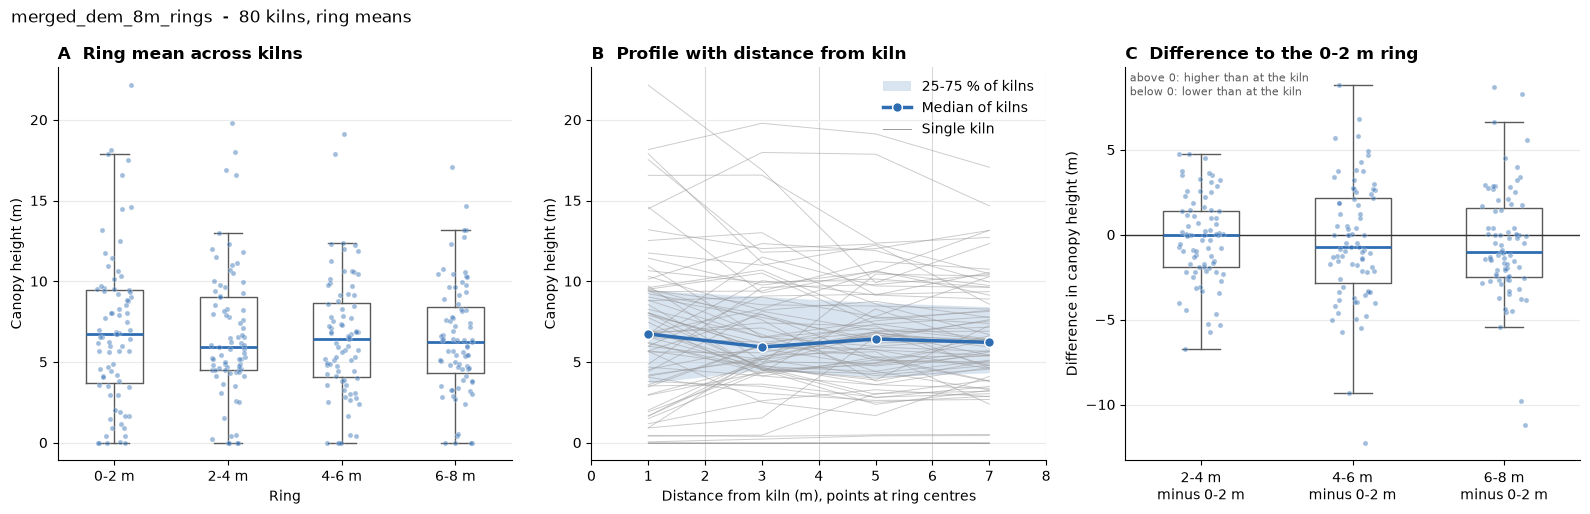

In [73]:
fig = plot_kiln_rings({
    "rings_csv": out_8["files"]["rings"],
    "value": "mean",
    "y_label": VALUE_LABEL,
})

## 3. Ringanalyse 0–50 m

Zehn Ringe à 5 m. Mit grösserem Radius laufen die Strahlen auseinander (bei 50 m und 32 Strahlen knapp 10 m Abstand am äusseren Rand), deshalb werden 32 statt 16 Strahlen verwendet. Mit `n_rays = 64` ist die Fläche besser abgedeckt, die Analyse dauert dann etwa doppelt so lange.

In [74]:
params_50m = {
    **BASE,
    "rings": [(i, i + 5) for i in range(0, 50, 5)],
    "n_rays": 32,
    "step": 1,
    "out_prefix": "merged_dem_50m",
}
out_50 = kiln_ring_analysis(params_50m)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          32 (every 11.25°), sample every 1 m up to 50 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-5     m: 160 samples
       5-10    m: 160 samples
      10-15    m: 160 samples
      15-20    m: 160 samples
      20-25    m: 160 samples
      25-30    m: 160 samples
      30-35    m: 160 samples
      35-40    m: 160 samples
      40-45    m: 160 samples
      45-50    m: 160 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-5 m  5-10 m  10-15 m  15-20 m  20-25 m  25-30 m  30-35 m  35-40 m  \
count   79.00   79.00    79.00    79.00    79.00    79.00    78.00    79.00   
median   6.41    5.91     5.87     6.14     6.13     6.05     6.11     6.09   
mean     6.79    6.51     6.46     6.41     6.50     6.38     6

## 3. Ringanalyse 0–25 m

In [87]:
params_25m = {
    **BASE,
    "rings": [(i, i + 5) for i in range(0, 25, 5)],     # 0-5, 5-10, 10-15, 15-20, 20-25 m
    "n_rays": 32,
    "step": 1,
    "out_prefix": "merged_dem_25m",
}
out_25 = kiln_ring_analysis(params_25m)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          32 (every 11.25°), sample every 1 m up to 25 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-5     m: 160 samples
       5-10    m: 160 samples
      10-15    m: 160 samples
      15-20    m: 160 samples
      20-25    m: 160 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-5 m  5-10 m  10-15 m  15-20 m  20-25 m
count   79.00   79.00    79.00    79.00    79.00
median   6.41    5.91     5.87     6.14     6.13
mean     6.79    6.51     6.46     6.41     6.50
std      3.98    3.50     3.65     3.39     3.26
min      0.00    0.00     0.00     0.00     0.41
25%      4.46    4.50     4.51     4.64     4.73
50%      6.41    5.91     5.87     6.14     6.13
75%      8.57    8.89     8.08     7.61     7.85
max     1

## 4. Räumliche Lage der Kilns

Liegen zwei Kilns näher als 2 × Radius beieinander, teilen sich ihre Kreise Pixel. Die Kilns sind dann nicht unabhängig voneinander. Der Abschnitt zeigt, wie viele Kilns betroffen sind, und bildet Gruppen (Kilns, die über Nachbarn unter 200 m verbunden sind).

In [75]:
id_col = BASE["id_column"]
k = gpd.read_file(BASE["gpkg"]).set_index(id_col)
xy = np.c_[k.geometry.x, k.geometry.y]
D = cdist(xy, xy)
np.fill_diagonal(D, np.inf)
nn = pd.Series(D.min(axis=1), index=k.index)          # Abstand zum nächsten anderen Kiln (m)

print(nn.describe().round(0))
print()
for R in (8, 25, 50, 100):
    print(f"Radius {R:>3} m: {(nn < 2 * R).sum():>2} von {len(nn)} Kilns teilen Fläche mit einem Nachbarn")

n_clusters, lab = connected_components(D < 200, directed=False)
cluster = pd.Series(lab, index=k.index, name="cluster")
print(f"\n{n_clusters} Gruppen (Kilns, die über Nachbarn < 200 m verbunden sind)")
print("Gruppengrösse -> Anzahl Gruppen:", cluster.value_counts().value_counts().sort_index().to_dict())

count       80.0
mean       324.0
std       1178.0
min         60.0
25%         89.0
50%        113.0
75%        218.0
max      10562.0
dtype: float64

Radius   8 m:  0 von 80 Kilns teilen Fläche mit einem Nachbarn
Radius  25 m:  0 von 80 Kilns teilen Fläche mit einem Nachbarn
Radius  50 m: 34 von 80 Kilns teilen Fläche mit einem Nachbarn
Radius 100 m: 59 von 80 Kilns teilen Fläche mit einem Nachbarn

37 Gruppen (Kilns, die über Nachbarn < 200 m verbunden sind)
Gruppengrösse -> Anzahl Gruppen: {1: 21, 2: 5, 3: 3, 4: 2, 5: 4, 6: 2}


## 5. Ringmittel und Streuung (SD)

Oben: Mittlere Kronenhöhe pro Ring, ein Wert pro Kiln. Unten: Standardabweichung der Messwerte innerhalb eines Rings, ein Wert pro Kiln und Ring.

**Hinweis zur SD:** Die SD wächst mit dem Radius allein aus geometrischen Gründen (äussere Ringe decken mehr Fläche ab). Sie darf deshalb nicht direkt zwischen den Ringen verglichen werden, sondern nur gegen Kontrollpunkte (Abschnitt 8).

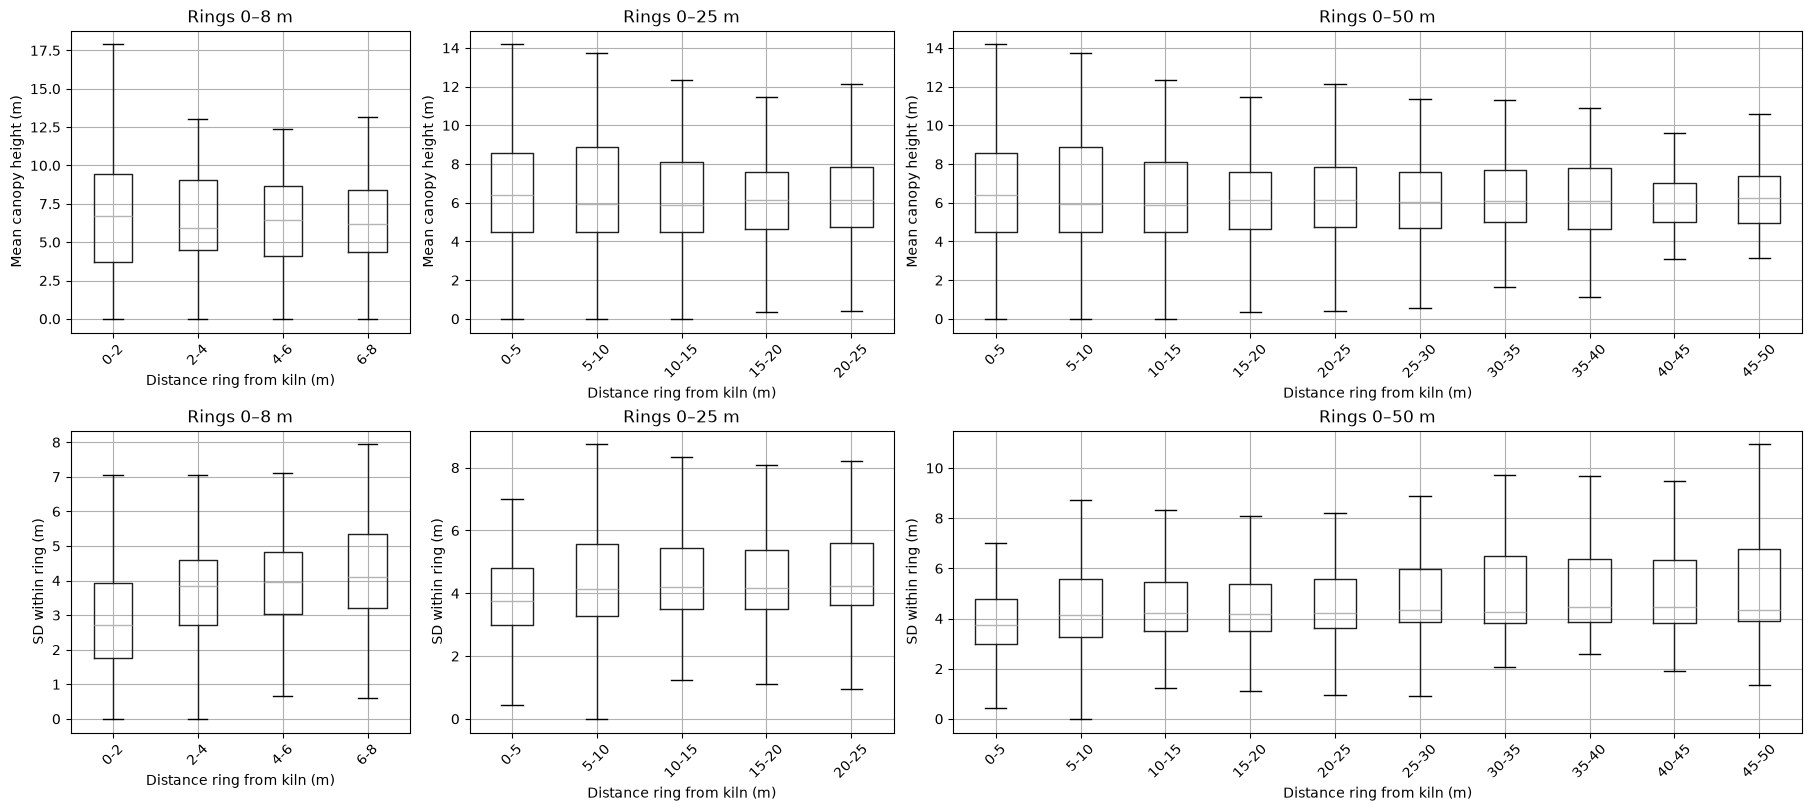

In [89]:
scales = {"0–8 m": out_8, "0–25 m": out_25, "0–50 m": out_50}

fig, axes = plt.subplots(2, len(scales), figsize=(18, 8), layout="constrained",
                         gridspec_kw={"width_ratios": [len(o["params"]["rings"]) for o in scales.values()]})
tables = {}

for col, (name, o) in enumerate(scales.items()):
    rings = o["params"]["rings"]
    labels = [f"{a}-{b}" for a, b in rings]

    mean = o["rings"][[f"mean_{a}_{b}" for a, b in rings]].set_axis(labels, axis=1)

    g = o["samples"].query("ring_index >= 0").groupby(["kiln_id", "ring_index"])
    sd = g["value"].std().unstack().where(g["valid"].mean().unstack() >= o["params"]["min_valid"])
    sd.columns = labels

    tables[name] = {"mean": mean, "sd": sd}

    for row, (tab, ylab) in enumerate([(mean, "Mean canopy height (m)"), (sd, "SD within ring (m)")]):
        ax = axes[row, col]
        tab.boxplot(ax=ax, showfliers=False)
        ax.set_title(f"Rings {name}")
        ax.set_xlabel("Distance ring from kiln (m)")
        ax.set_ylabel(ylab)
        ax.tick_params(axis="x", rotation=45)

plt.show()

In [77]:
tables["0–8 m"]["sd"].describe().round(2)

,0-2,2-4,4-6,6-8
count,79.00,79.00,79.00,79.00
mean,2.97,3.78,4.02,4.30
std,1.87,1.95,1.94,2.07
min,0.00,0.00,0.00,0.00
25%,1.77,2.72,3.04,3.21
50%,2.70,3.84,3.96,4.11
75%,3.92,4.59,4.82,5.33
max,8.64,9.52,10.26,10.04


## 6. Vier ausgewählte Kilns

Ausgewählt wird nach den Ringmitteln aus `out["rings"]`:

- **Lowest at kiln:** Mittel im Innenring minus Mittel im Aussenring ist am kleinsten (Bewuchs am Kiln niedriger als aussen).
- **Highest at kiln:** dieselbe Differenz ist am grössten.
- **No difference:** die Differenz liegt am nächsten bei 0 (nur Kilns mit Bewuchs im Aussenring).
- **Largest spread between rings:** grösster Unterschied zwischen zwei beliebigen Ringmitteln.

**Karte (oben):** Kronenhöhe, Ringgrenzen (gestrichelt), Kiln (rotes Kreuz) und die Messrichtungen (schwarze Linien). **Profil (unten):** Kronenhöhe entlang jedes Strahls (grau) und deren Mittel (blau).

Die Extreme aus 80 Kilns sehen auch ohne echten Effekt auffällig aus. Sie sind Beispiele zum Anschauen und kein Beleg für einen Kiln-Effekt.

                  x           y  mean_0_2  mean_6_8  delta  spread
kiln_id                                                           
6        2809141.07  1169552.43      1.64     10.32  -8.68    8.80
37       2811344.24  1171510.22     17.89      6.69  11.20   11.20
2        2808256.88  1171884.12      0.00      0.00  -0.00    0.00
29       2810803.88  1170657.46     22.14     12.33   9.81   12.24


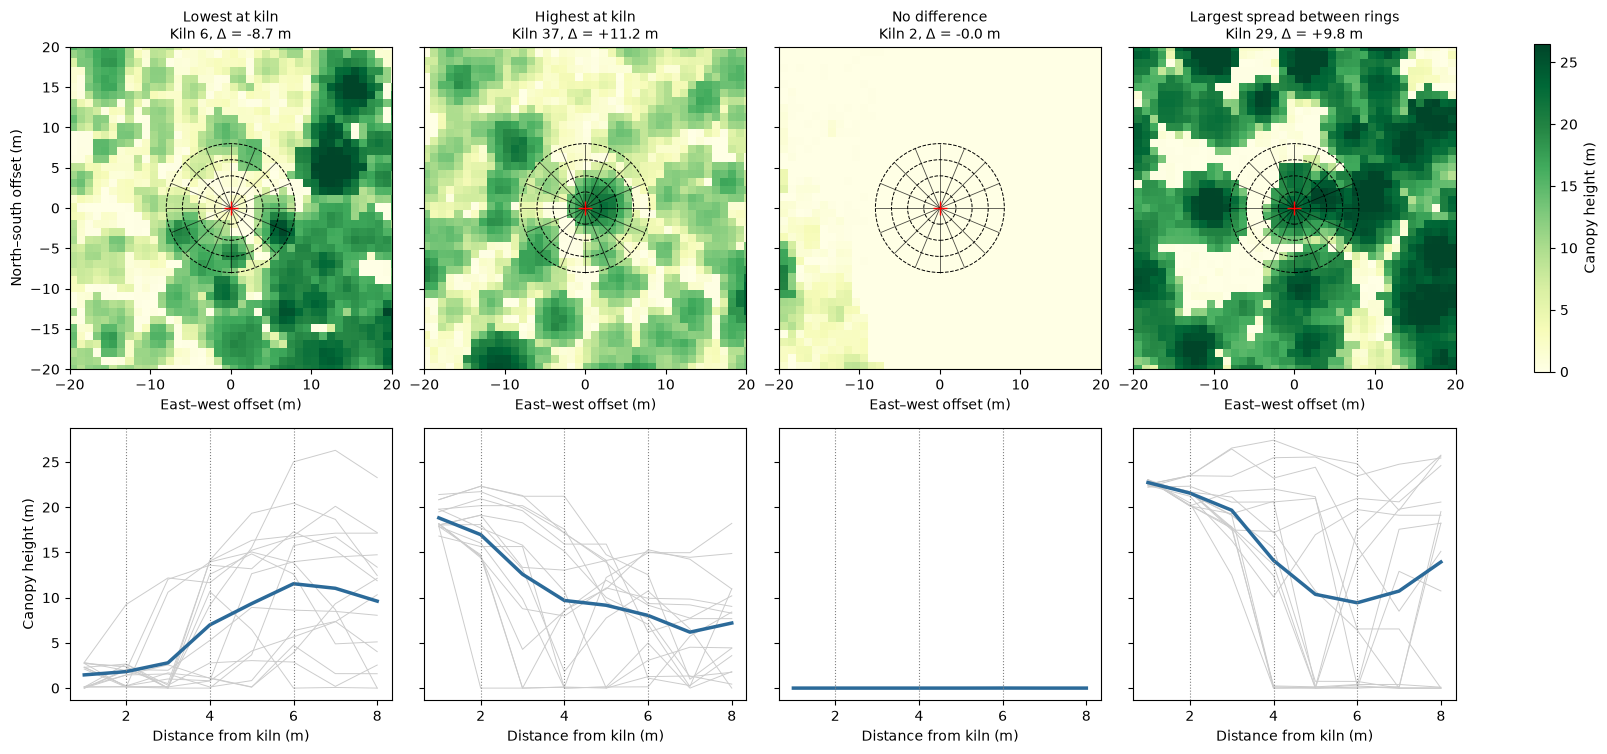

In [78]:
# --- Einstellungen ---------------------------------------------------------------
o = out_8              # out_8 (0–8 m) oder out_50 (0–50 m)
half = 20              # m: halbe Kantenlänge des Kartenausschnitts (out_8: 20 oder 12, out_50: 60)
png_path = "results/four_kilns.png"

rings = o["params"]["rings"]
inner = f"mean_{rings[0][0]}_{rings[0][1]}"
outer = f"mean_{rings[-1][0]}_{rings[-1][1]}"
mean_cols = [f"mean_{a}_{b}" for a, b in rings]

# --- Auswahl ---------------------------------------------------------------------
r = o["rings"].copy()
r["delta"] = r[inner] - r[outer]                                    # Innenring minus Aussenring
r["spread"] = r[mean_cols].max(axis=1) - r[mean_cols].min(axis=1)   # grösster Unterschied zwischen zwei Ringen
r = r.dropna(subset=["delta"])

picks = {
    "Lowest at kiln":  r["delta"].idxmin(),
    "Highest at kiln": r["delta"].idxmax(),
    "No difference":   r[r[outer] > 0]["delta"].abs().idxmin(),
}
picks["Largest spread between rings"] = r.drop(list(picks.values()))["spread"].idxmax()

print(r.loc[list(picks.values()), ["x", "y", inner, outer, "delta", "spread"]].round(2))

# --- Rasterausschnitt um jeden gewählten Kiln ------------------------------------
maps = {}
with rasterio.open(o["params"]["tif"]) as src:
    n = int(half / src.res[0])
    for title, kid in picks.items():
        x, y = r.loc[kid, "x"], r.loc[kid, "y"]
        row, col = src.index(x, y)
        win = Window(col - n, row - n, 2 * n + 1, 2 * n + 1)
        arr = src.read(o["params"]["band"], window=win, boundless=True, masked=True)
        arr = arr.astype("float64").filled(np.nan)
        t = src.window_transform(win)
        ext = (t.c - x, t.c + win.width * t.a - x,              # Koordinaten relativ zum Kiln
               t.f + win.height * t.e - y, t.f - y)
        maps[kid] = (arr, ext)

# --- Abbildung: oben Karte mit Messrichtungen, unten Profil ----------------------
s = o["samples"]
vmax = np.nanpercentile(np.concatenate([a.ravel() for a, _ in maps.values()]), 98)
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharey="row",
                         gridspec_kw={"height_ratios": [3, 2]}, layout="constrained")

for i, (title, kid) in enumerate(picks.items()):
    arr, ext = maps[kid]
    kx, ky = r.loc[kid, "x"], r.loc[kid, "y"]
    sk = s[(s["kiln_id"] == kid) & (s["ray"] >= 0)]            # Messpunkte dieses Kilns ohne Mittelpunkt

    ax = axes[0, i]
    im = ax.imshow(arr, extent=ext, cmap="YlGn", vmin=0, vmax=vmax)
    far = sk.sort_values("distance").groupby("ray").tail(1)    # äusserster Messpunkt jedes Strahls
    segs = [[(0, 0), (fx - kx, fy - ky)] for fx, fy in zip(far["x"], far["y"])]
    ax.add_collection(LineCollection(segs, colors="k", linewidths=0.6, alpha=0.7))   # Messrichtungen
    for _, r_out in rings:
        ax.add_patch(plt.Circle((0, 0), r_out, fill=False, ec="k", ls="--", lw=0.7))
    ax.plot(0, 0, "r+", ms=10)
    ax.set_xlim(-half, half)
    ax.set_ylim(-half, half)
    ax.set_title(f"{title}\nKiln {kid}, Δ = {r.loc[kid, 'delta']:+.1f} m", fontsize=10)
    ax.set_xlabel("East–west offset (m)")
    if i == 0:
        ax.set_ylabel("North–south offset (m)")

    ax = axes[1, i]
    prof = sk.pivot(index="distance", columns="ray", values="value")
    ax.plot(prof.index, prof.to_numpy(), color="0.8", lw=0.7)           # jeder Strahl
    ax.plot(prof.index, prof.mean(axis=1), color="#2b6a99", lw=2.5)     # Mittel über die Strahlen
    for _, r_out in rings[:-1]:
        ax.axvline(r_out, color="0.5", ls=":", lw=0.8)
    ax.set_xlabel("Distance from kiln (m)")
    if i == 0:
        ax.set_ylabel(VALUE_LABEL)

fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=VALUE_LABEL)
fig.savefig(png_path, dpi=200, bbox_inches="tight")
plt.show()

## 7. Überblick über alle Kilns (PDF)

Dieselbe Abbildung für jeden einzelnen Kiln, vier Kilns pro Seite. Die Reihenfolge geht vom stärksten Abfall (Bewuchs am Kiln niedriger als aussen) bis zum stärksten Anstieg, Kilns ohne Δ stehen am Ende. Alle Karten haben dieselbe Farbskala. Zusätzlich wird eine Tabelle mit Koordinaten, Ringmitteln und Δ gespeichert.

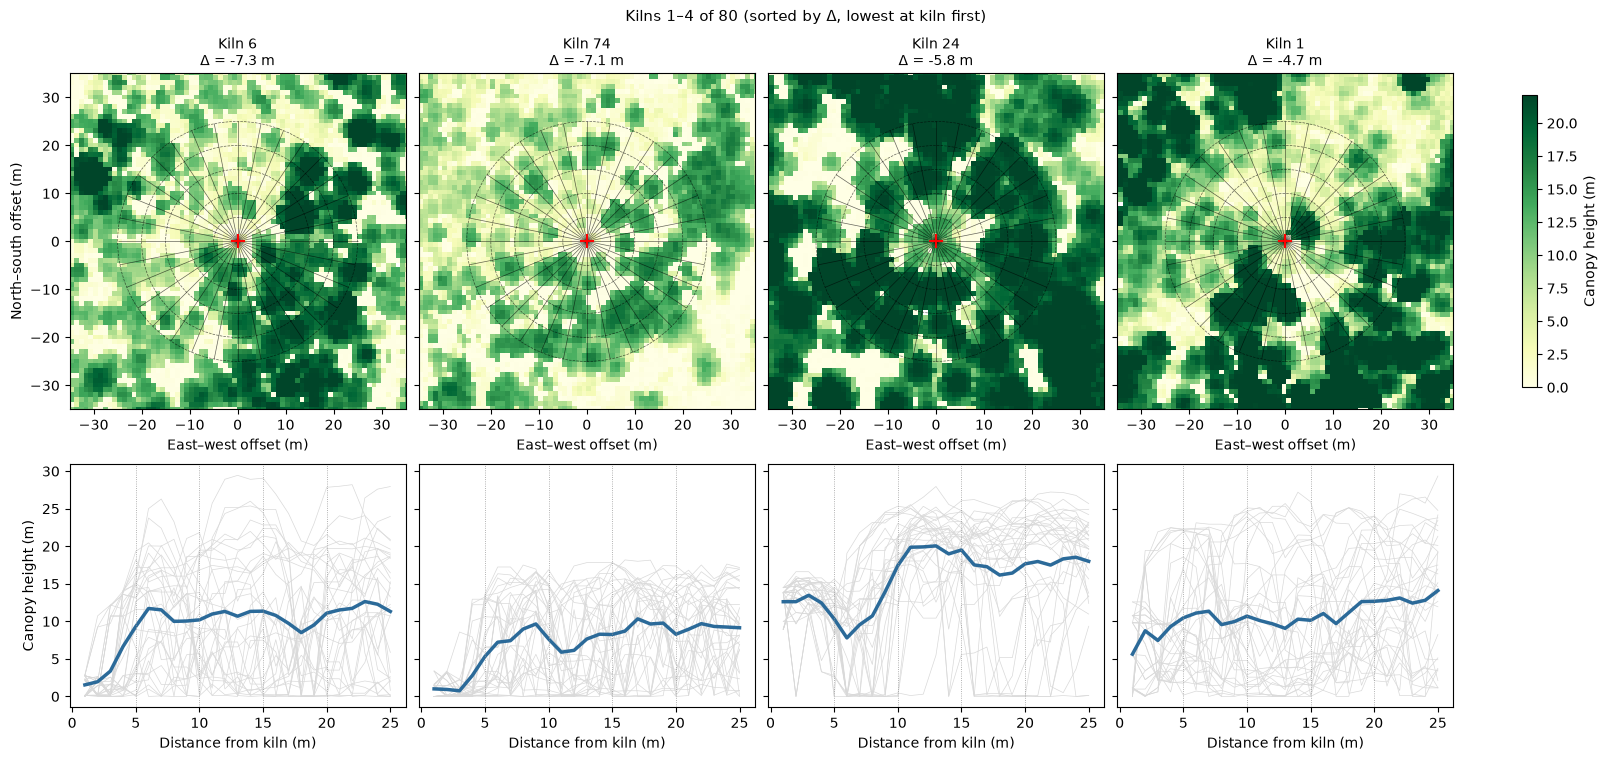

20 Seiten gespeichert: results/all_kilns_25m.pdf


In [88]:
# --- Einstellungen ---------------------------------------------------------------
o = out_25             # out_8 (0–8 m), out_25 (0–25 m) oder out_50 (0–50 m)
half = 35              # m: halbe Kantenlänge des Kartenausschnitts (out_8: 20, out_25: 35, out_50: 60)
per_page = 4           # Kilns pro Seite
pdf_path = "results/all_kilns_25m.pdf"
csv_path = "results/kilns_delta_25m.csv"

rings = o["params"]["rings"]
inner = f"mean_{rings[0][0]}_{rings[0][1]}"
outer = f"mean_{rings[-1][0]}_{rings[-1][1]}"
mean_cols = [f"mean_{a}_{b}" for a, b in rings]

# --- Δ für alle Kilns ------------------------------------------------------------
r = o["rings"].copy()
r["delta"] = r[inner] - r[outer]
r = r.sort_values("delta", na_position="last")
r[["x", "y"] + mean_cols + ["delta"]].to_csv(csv_path)

# --- Rasterausschnitt um jeden Kiln ----------------------------------------------
maps = {}
with rasterio.open(o["params"]["tif"]) as src:
    n = int(half / src.res[0])
    for kid in r.index:
        x, y = r.loc[kid, "x"], r.loc[kid, "y"]
        row, col = src.index(x, y)
        win = Window(col - n, row - n, 2 * n + 1, 2 * n + 1)
        arr = src.read(o["params"]["band"], window=win, boundless=True, masked=True)
        arr = arr.astype("float64").filled(np.nan)
        t = src.window_transform(win)
        ext = (t.c - x, t.c + win.width * t.a - x,
               t.f + win.height * t.e - y, t.f - y)
        maps[kid] = (arr, ext)

vmax = np.nanpercentile(np.concatenate([a.ravel() for a, _ in maps.values()]), 98)

# --- PDF: eine Seite pro vier Kilns ----------------------------------------------
s = o["samples"]
order = list(r.index)
pages = [order[i:i + per_page] for i in range(0, len(order), per_page)]

with PdfPages(pdf_path) as pdf:
    for pg, page_kilns in enumerate(pages):
        fig, axes = plt.subplots(2, per_page, figsize=(16, 7.5), sharey="row",
                                 gridspec_kw={"height_ratios": [3, 2]}, layout="constrained")
        for i in range(per_page):
            if i >= len(page_kilns):                       # letzte Seite: leere Spalten ausblenden
                axes[0, i].axis("off")
                axes[1, i].axis("off")
                continue
            kid = page_kilns[i]
            arr, ext = maps[kid]
            kx, ky = r.loc[kid, "x"], r.loc[kid, "y"]
            sk = s[(s["kiln_id"] == kid) & (s["ray"] >= 0)]
            d = r.loc[kid, "delta"]
            d_txt = "n/a" if np.isnan(d) else f"{d:+.1f} m"

            ax = axes[0, i]
            im = ax.imshow(arr, extent=ext, cmap="YlGn", vmin=0, vmax=vmax)
            far = sk.sort_values("distance").groupby("ray").tail(1)
            segs = [[(0, 0), (fx - kx, fy - ky)] for fx, fy in zip(far["x"], far["y"])]
            ax.add_collection(LineCollection(segs, colors="k", linewidths=0.5, alpha=0.6))
            for _, r_out in rings:
                ax.add_patch(plt.Circle((0, 0), r_out, fill=False, ec="k", ls="--", lw=0.5, alpha=0.6))
            ax.plot(0, 0, "r+", ms=10, mew=1.5)
            near = o["rings"][["x", "y"]].drop(kid)                              # alle anderen Kilns
            near = near[((near["x"] - kx).abs() <= half) & ((near["y"] - ky).abs() <= half)]   # nur im Ausschnitt
            ax.plot(near["x"] - kx, near["y"] - ky, "o", mfc="none", mec="red", ms=6, mew=1.5)
            ax.set_xlim(-half, half)
            ax.set_ylim(-half, half)
            ax.set_title(f"Kiln {kid}\nΔ = {d_txt}", fontsize=10)
            ax.set_xlabel("East–west offset (m)")
            if i == 0:
                ax.set_ylabel("North–south offset (m)")

            ax = axes[1, i]
            prof = sk.pivot(index="distance", columns="ray", values="value")
            ax.plot(prof.index, prof.to_numpy(), color="0.85", lw=0.5)
            ax.plot(prof.index, prof.mean(axis=1), color="#2b6a99", lw=2.5)
            for _, r_out in rings[:-1]:
                ax.axvline(r_out, color="0.6", ls=":", lw=0.6)
            ax.set_xlabel("Distance from kiln (m)")
            if i == 0:
                ax.set_ylabel(VALUE_LABEL)

        fig.colorbar(im, ax=[a for a in axes[0] if a.axison], shrink=0.8, label=VALUE_LABEL)
        fig.suptitle(f"Kilns {pg * per_page + 1}–{pg * per_page + len(page_kilns)} of {len(order)} "
                     f"(sorted by Δ, lowest at kiln first)", fontsize=11)
        pdf.savefig(fig)
        if pg == 0:
            plt.show()                                     # erste Seite direkt im Notebook
        else:
            plt.close(fig)

print(f"{len(pages)} Seiten gespeichert: {pdf_path}")

## 8. Kontrollpunkte (optional)

Ein Gradient um die Kilns allein beweist keinen Kiln-Effekt: Die Köhler haben ihre Plätze nicht zufällig gewählt, und auch um beliebige Punkte unterscheiden sich innere und äussere Ringe (Geometrie, Gelände). Deshalb wird dieselbe Analyse an Kontrollpunkten wiederholt, die **nahe** bei jedem Kiln liegen (gleicher Hang, ähnlicher Wald), aber nicht auf dem Kiln.

Dieser Abschnitt gilt für die Skala **0–8 m**. Für grössere Radien müssten die Kontrollpunkte mindestens 2 × Radius vom Kiln entfernt liegen, sonst überlappen sich die Messbereiche.

**Waldfilter:** Kontrollpunkte auf Wiese, Fels oder Geröll würden den Vergleich verfälschen. Ein Punkt gilt als Wald, wenn die mittlere Höhe im Ring 60–100 m um ihn mindestens `min_height` beträgt. Dieser Ring liegt ausserhalb des Messbereichs und der Kontrollzone, damit nicht nach dem gefiltert wird, was gemessen wird. Kilns und Kontrollpunkte werden mit derselben Schwelle gefiltert.

### 8.1 Kontrollpunkte erzeugen

In [83]:
id_col = BASE["id_column"]
kilns = gpd.read_file(BASE["gpkg"]).reset_index(drop=True)

rng = np.random.default_rng(42)
n_per_kiln = 5            # Kontrollpunkte pro Kiln
d_min, d_max = 30, 60     # Abstand zum eigenen Kiln (m)
safe = 30                 # Mindestabstand zu allen anderen Kilns (m)

ids, parents, pts = [], [], []
for i, (kid, geom) in enumerate(zip(kilns[id_col], kilns.geometry)):
    others = kilns.geometry.drop(i)
    n, tries = 0, 0
    while n < n_per_kiln and tries < 500:
        tries += 1
        rad = np.sqrt(rng.uniform(d_min**2, d_max**2))       # gleichmässig über die Fläche
        ang = rng.uniform(0, 2 * np.pi)
        pt = Point(geom.x + rad * np.sin(ang), geom.y + rad * np.cos(ang))
        if others.distance(pt).min() < safe:
            continue
        ids.append(f"{kid}_{n}")
        parents.append(kid)
        pts.append(pt)
        n += 1

if not pts:
    raise RuntimeError("Kein Kontrollpunkt akzeptiert: safe verkleinern oder d_max vergrössern.")

ctrl = gpd.GeoDataFrame({id_col: ids, "parent": parents}, geometry=pts, crs=kilns.crs)
ctrl_path = "results/control_points.gpkg"
ctrl.to_file(ctrl_path, driver="GPKG")

print(len(ctrl), "Kontrollpunkte")
print("Kilns ohne Kontrollpunkt:", sorted(set(kilns[id_col]) - set(ctrl["parent"])))

400 Kontrollpunkte
Kilns ohne Kontrollpunkt: []


### 8.2 Analyse der Kontrollpunkte und Waldfilter

Schaut euch die beiden Verteilungen an, bevor ihr die Schwelle in 8.3 festlegt. Sie soll Fels, Wiese und Gewässer ausschliessen, aber nicht die Kilns selbst.

In [84]:
res_ctrl = kiln_ring_analysis({**params_8m, "gpkg": ctrl_path, "save": False, "verbose": False})

far = {"rings": [(60, 100)], "step": 5, "save": False, "verbose": False}
far_k = kiln_ring_analysis({**params_8m, **far})["rings"]["mean_60_100"]
far_c = kiln_ring_analysis({**params_8m, "gpkg": ctrl_path, **far})["rings"]["mean_60_100"]

print("Mittlere Höhe im Ring 60–100 m, Kilns:");          print(far_k.describe().round(1))
print("\nMittlere Höhe im Ring 60–100 m, Kontrollpunkte:"); print(far_c.describe().round(1))

Mittlere Höhe im Ring 60–100 m, Kilns:
count    79.0
mean      6.4
std       2.2
min       1.7
25%       5.0
50%       5.9
75%       7.4
max      13.0
Name: mean_60_100, dtype: float64

Mittlere Höhe im Ring 60–100 m, Kontrollpunkte:
count    395.0
mean       6.5
std        2.4
min        0.7
25%        5.1
50%        6.1
75%        7.4
max       16.5
Name: mean_60_100, dtype: float64


### 8.3 Vergleich Kiln gegen Kontrolle

Pro Kiln wird der Median seiner Kontrollpunkte gebildet (ein Kontrollwert pro Kiln). Dann wird die Differenz **Kiln minus Kontrolle** pro Ring berechnet und gepaart mit dem Wilcoxon-Test gegen 0 geprüft. Boxen um 0 heissen: kein Unterschied zwischen Kiln und Umgebung. Bei vier Ringen gleichzeitig getestet werden die p-Werte mit 4 multipliziert (Bonferroni).

Kilns im Wald: 59 von 80
Kontrollpunkte im Wald: 300 von 400

--- mean: 59 Kilns mit gültigem Kontrollwert
0-2 m: Median +1.01, n = 59, Wilcoxon p = 0.0853
2-4 m: Median +0.40, n = 59, Wilcoxon p = 0.3712
4-6 m: Median +0.00, n = 59, Wilcoxon p = 0.9352
6-8 m: Median +0.00, n = 59, Wilcoxon p = 0.7188

--- sd: 59 Kilns mit gültigem Kontrollwert
0-2 m: Median -0.25, n = 59, Wilcoxon p = 0.5310
2-4 m: Median +0.00, n = 59, Wilcoxon p = 0.8435
4-6 m: Median +0.00, n = 59, Wilcoxon p = 0.4365
6-8 m: Median -0.23, n = 59, Wilcoxon p = 0.3508


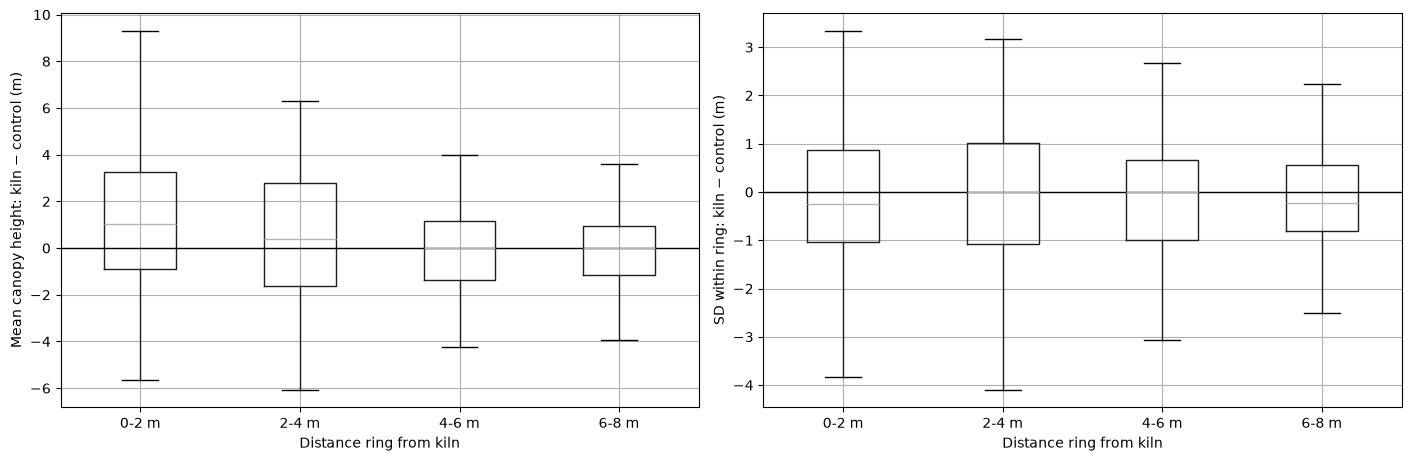

In [85]:
min_height = 5      # m: nach der Verteilung in 8.2 anpassen

kiln_ok = far_k.index[far_k >= min_height]
ctrl_ok = far_c.index[far_c >= min_height]
print(f"Kilns im Wald: {len(kiln_ok)} von {len(far_k)}")
print(f"Kontrollpunkte im Wald: {len(ctrl_ok)} von {len(far_c)}")

rings = out_8["params"]["rings"]
labels = [f"{a}-{b} m" for a, b in rings]
mean_cols = [f"mean_{a}_{b}" for a, b in rings]
parent = dict(zip(ctrl[id_col], ctrl["parent"]))

# Mittel und SD pro Ring für Kilns und Kontrollpunkte
tabs = {}
for who, o in {"kilns": out_8, "controls": res_ctrl}.items():
    g = o["samples"].query("ring_index >= 0").groupby(["kiln_id", "ring_index"])
    sd = g["value"].std().unstack().where(g["valid"].mean().unstack() >= o["params"]["min_valid"])
    sd.columns = labels
    tabs[who] = {"mean": o["rings"][mean_cols].set_axis(labels, axis=1), "sd": sd}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), layout="constrained")
for ax, (key, ylab) in zip(axes, [("mean", "Mean canopy height: kiln − control (m)"),
                                  ("sd", "SD within ring: kiln − control (m)")]):
    kt = tabs["kilns"][key]
    kt = kt.loc[kt.index.intersection(kiln_ok)]
    ct = tabs["controls"][key]
    ct = ct.loc[ct.index.intersection(ctrl_ok)]
    ct_per_kiln = ct.groupby(ct.index.map(parent)).median()      # 1 Kontrollwert pro Kiln

    common = kt.index.intersection(ct_per_kiln.index)
    diff = kt.loc[common] - ct_per_kiln.loc[common]               # Kiln minus Kontrolle

    diff.boxplot(ax=ax, showfliers=False)
    ax.axhline(0, color="k", lw=1)
    ax.set_xlabel("Distance ring from kiln")
    ax.set_ylabel(ylab)

    print(f"\n--- {key}: {len(common)} Kilns mit gültigem Kontrollwert")
    for col in diff.columns:
        d = diff[col].dropna()
        p = wilcoxon(d).pvalue if len(d) > 5 else np.nan
        print(f"{col}: Median {d.median():+.2f}, n = {len(d)}, Wilcoxon p = {p:.4f}")

plt.show()